In [1]:
import os
import utils
import torch
import pickle
import numpy as np
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import ConfusionMatrixDisplay

# PARAMETRI

In [2]:
EPOCHS = 200
BATCH_SIZE = 8
LEARNING_RATE = 0.001
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


CLASSI: ['Standing', 'Running', 'Walking', 'Badminton']
SHAPE: X_TRAIN = (40, 100, 6), Y_TRAIN = (40,)
SHAPE: X_TEST = (40, 100, 6), Y_TEST = (40,)
SERIE PER CLASSE (train): [10 10 10 10]



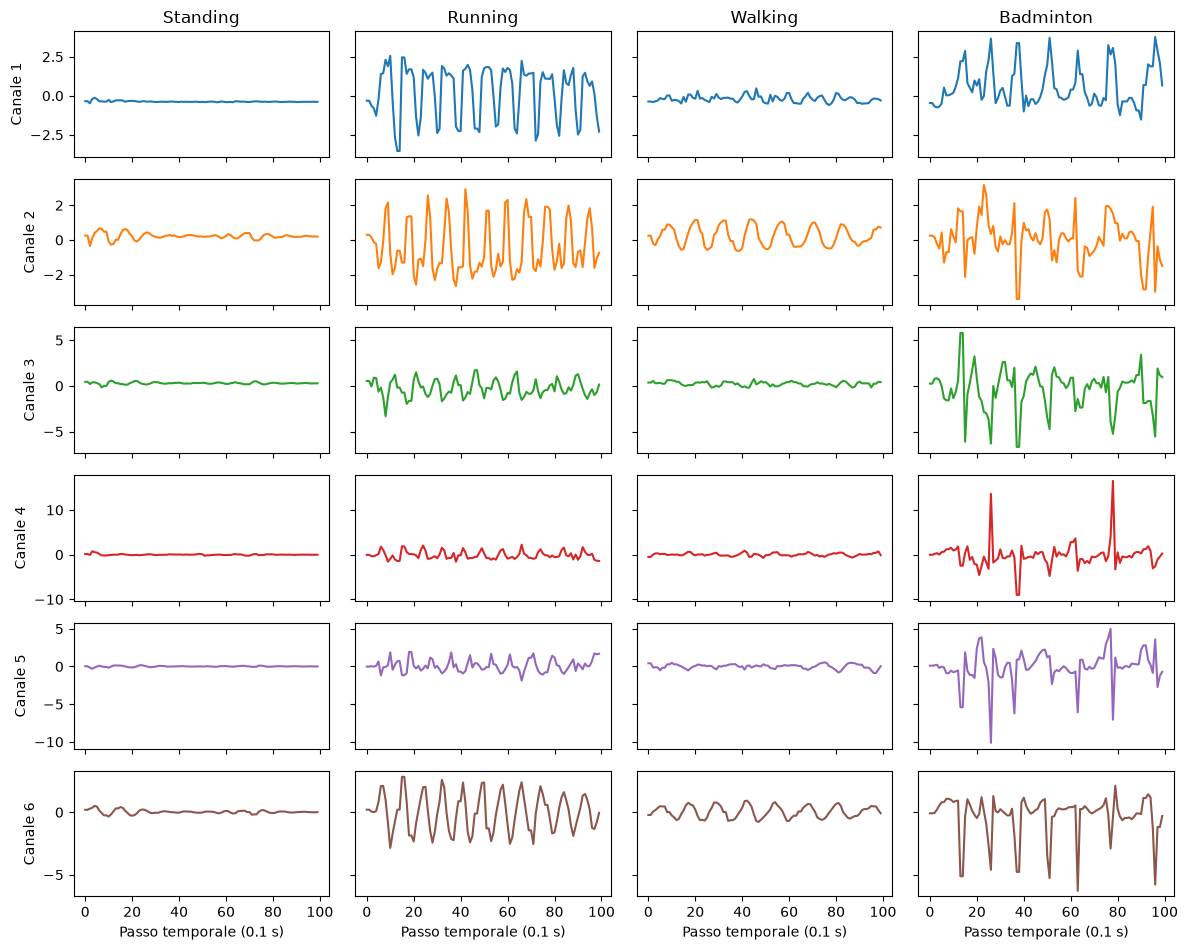

In [3]:
from datasets.datasets import load_BASICMOTIONS
(x_train, y_train), (x_test, y_test), classes = load_BASICMOTIONS()

# DATASET: 6 canali (accelerometro e giroscopio, 3 assi ciascuno) per 100 passi temporali, 4 attività
print(f"CLASSI: {classes}")
print(f"SHAPE: X_TRAIN = {x_train.shape}, Y_TRAIN = {y_train.shape}")   # (serie, passi temporali, canali)
print(f"SHAPE: X_TEST = {x_test.shape}, Y_TEST = {y_test.shape}")
print(f"SERIE PER CLASSE (train): {np.bincount(y_train)}\n")

# Standardizzazione per canale, con media e deviazione standard calcolate solo sul training set
mean = x_train.mean(axis=(0, 1), keepdims=True)
std = x_train.std(axis=(0, 1), keepdims=True)
x_train = (x_train - mean) / std
x_test = (x_test - mean) / std

train_dataset = TensorDataset(torch.tensor(x_train), torch.tensor(y_train))
test_dataset = TensorDataset(torch.tensor(x_test), torch.tensor(y_test))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Una serie per classe (colonne), un canale per riga: stessa scala lungo ogni riga per confrontare le classi
n_channels = x_train.shape[2]
fig, axes = plt.subplots(n_channels, len(classes), figsize=(12, 1.6 * n_channels), sharex=True, sharey='row')
for c, name in enumerate(classes):
    series = x_train[np.where(y_train == c)[0][0]]          # (100, 6)
    axes[0, c].set_title(name)
    axes[-1, c].set_xlabel('Passo temporale (0.1 s)')
    for ch in range(n_channels):
        axes[ch, c].plot(series[:, ch], color=f'C{ch}')
for ch in range(n_channels):
    axes[ch, 0].set_ylabel(f'Canale {ch + 1}')
plt.tight_layout()
plt.show()

# MODELLO

In [4]:
#Parametri del modello
INPUT_SIZE = x_train.shape[2]     # 6 canali
HIDDEN_SIZE = 32
NUM_CLASSES = len(classes)        # 4 attività

In [5]:
# nn.RNN, nn.LSTM e nn.GRU restituiscono (output, stato), quindi non si possono mettere direttamente in un nn.Sequential
class RNNClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super().__init__()
        self.rnn = nn.LSTM(input_size, hidden_size, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):                          # (B, 100, 6): 100 passi da 6 valori
        out, _ = self.rnn(x)                       # (B, 100, HIDDEN_SIZE)
        return self.fc(out[:, -1])                 # uscita dell'ultimo passo -> logit (B, NUM_CLASSES)

torch.manual_seed(7)
model = RNNClassifier(INPUT_SIZE, HIDDEN_SIZE, NUM_CLASSES).to(DEVICE)

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, eps=1e-7)
criterion = nn.CrossEntropyLoss()                 # applica internamente la softmax: il modello restituisce i logit

print(model)

RNNClassifier(
  (rnn): LSTM(6, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=4, bias=True)
)


# ADDESTRAMENTO

  0%|          | 0/200 [00:00<?, ?it/s]

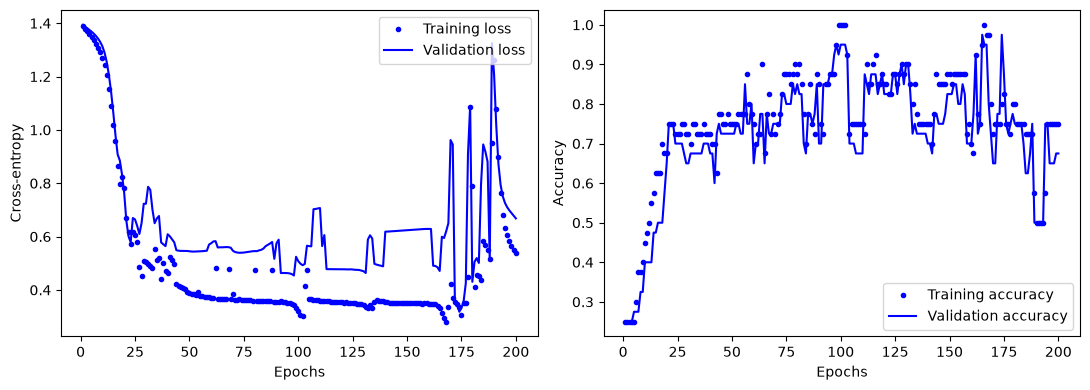

In [6]:
os.makedirs('histories', exist_ok=True)
filename = f"timeseries_classifier"   # file diversi per celle e dimensioni diverse

hist_path = f'histories/{filename}.hist'
weights_path = f'histories/{filename}.pt'
if os.path.isfile(hist_path) and os.path.isfile(weights_path):
    with open(hist_path, 'rb') as hist_file:
        history = pickle.load(hist_file)
    model.load_state_dict(torch.load(weights_path, map_location=DEVICE))
else:
    history = utils.train(model, optimizer, criterion, train_loader, test_loader, EPOCHS, DEVICE)
    with open(hist_path, 'wb') as hist_file:
        pickle.dump(history, hist_file)
    torch.save(model.state_dict(), weights_path)

epochs = range(1, len(history['loss']) + 1)
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, history['loss'], 'bo', markersize=3, label='Training loss')
plt.plot(epochs, history['val_loss'], 'b', label='Validation loss')
plt.xlabel('Epochs')
plt.ylabel('Cross-entropy')
plt.legend(loc='upper right')
plt.subplot(1, 2, 2)
plt.plot(epochs, history['accuracy'], 'bo', markersize=3, label='Training accuracy')
plt.plot(epochs, history['val_accuracy'], 'b', label='Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# VALUTAZIONE

accuracy train = 0.750   accuracy test = 0.675


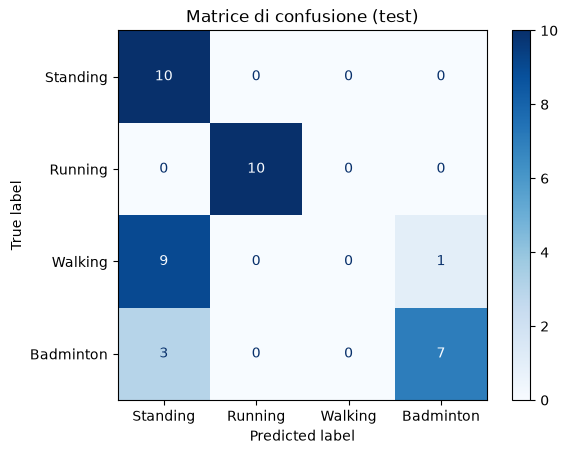

In [7]:
def predict(model, dataset):
    model.eval()
    x, _ = dataset.tensors
    with torch.no_grad():
        return model(x.to(DEVICE)).argmax(dim=1).cpu().numpy()

y_train_pred = predict(model, train_dataset)
y_test_pred = predict(model, test_dataset)
print(f"accuracy train = {np.mean(y_train_pred == y_train):.3f}   accuracy test = {np.mean(y_test_pred == y_test):.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, display_labels=classes, cmap='Blues')
plt.title(f'Matrice di confusione (test)')
plt.show()